# SPiCe Tutorial: Modelling Epithelial-Mesenchymal Plasticity

This notebook demonstrates the full SPiCe workflow for breast cancer Xenium
spatial transcriptomics data using the `spice.tl` / `spice.pl` API.

All tool functions modify `adata` in place — results are stored in
`adata.obs`, `adata.obsm` and `adata.uns['spice']`.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import enrichmap as em
import spice

In [4]:
sc.set_figure_params(frameon=False)

In [5]:
project_dir = "/home/cenk/Withnell_spice/"
os.chdir(project_dir)

figures_dir = project_dir +"figures/"

## 1. Load data into AnnData

In [6]:
adata = sc.read_h5ad(
    "/home/cenk/BreastCancerG0arrest/00_revisions/data/xenium_aligned_ductal_invasive.h5ad"
)

In [7]:
adata.obs["celltype_minor"].value_counts()

celltype_minor
Cancer Her2 SC                 16264
Cancer LumA SC                 11992
CAFs MSC iCAF-like             11247
CAFs myCAF-like                11098
Cancer Cycling                 10750
Mature Luminal                  6969
Cancer LumB SC                  6380
Cancer Basal SC                 6198
Macrophage                      5766
T cells CD4+                    5748
Myoepithelial                   5504
Cycling T-cells                 5281
Endothelial RGS5                4276
Cycling_Myeloid                 4186
DCs                             4040
T cells CD8+                    3757
Luminal Progenitors             3652
Endothelial ACKR1               2408
Plasmablasts                    2365
Monocyte                        2238
Endothelial CXCL12              1690
NK cells                        1622
NKT cells                       1588
B cells Memory                  1194
Endothelial Lymphatic LYVE1      889
PVL Differentiated               871
PVL Immature           

In [8]:
import decoupler as dc

hallmark = dc.op.hallmark()
emt_signature = hallmark[hallmark["source"] == "EPITHELIAL_MESENCHYMAL_TRANSITION"]["target"].values
emt_dict = {"EMT": emt_signature}

In [9]:
em.tl.score(adata, emt_dict)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring EMT: 20/200 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring EMT: 20/200 genes found: 100%|██████████| 1/1 [00:05<00:00,  5.37s/it]

Scoring EMT: 20/200 genes found: 100%|██████████| 1/1 [00:05<00:00,  5.37s/it]

In [10]:
adata.obs["tumour_cells"] = np.where(
    adata.obs["celltype_minor"].str.contains("Cancer"),
    "tumour",
    "non-tumour",
)

## 2. Assign discrete EMT state labels

In [11]:
spice.tl.assign_state_labels(
    adata,
    score_key="EMT_score",
    label_key="state_label",
    n_states=4,
    tumour_mask_key="tumour_cells",
)
print(adata.obs["state_label"].value_counts())

state_label
1    34830
2    34830
0    34830
3    34830
Name: count, dtype: int64


## 3. Build the spatial graph

In [12]:
spice.tl.build_graph(
    adata,
    spatial_key="spatial",
    n_neighbors=12,
    celltype_key="celltype_minor",
    label_key="state_label",
    score_key="EMT_score",
)

G = adata.uns["spice"]["graph"]
print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

Graph: 139320 nodes, 857949 edges


## 4. Cross-validate

In [13]:
spice.tl.cross_validate(
    adata,
    feature_mode="celltype",
)


Fold 1/5


  Epoch    0 | Loss 0.3440 | Test AUC: 0.6893


  Epoch  100 | Loss 0.2536 | Test AUC: 0.7969


  Epoch  200 | Loss 0.2489 | Test AUC: 0.8040


  Epoch  300 | Loss 0.2464 | Test AUC: 0.8061


  Epoch  400 | Loss 0.2459 | Test AUC: 0.8058


... (21 outputs left out)

  Epoch  200 | Loss 0.2453 | Test AUC: 0.7761


  Epoch  300 | Loss 0.2432 | Test AUC: 0.7757


  Epoch  400 | Loss 0.2414 | Test AUC: 0.7771


  Epoch  499 | Loss 0.2408 | Test AUC: 0.7784

Mean performance: 0.7951 ± 0.0252


## 5. Evaluate

In [14]:
spice.tl.evaluate(adata)
adata.uns["spice"]["auc"]

,fold,class,AUC
0,1,0,0.859985
1,1,1,0.698386
2,1,2,0.739141
3,1,3,0.933797
4,1,micro,0.808915
5,1,macro,0.807840
6,2,0,0.939591
7,2,1,0.674607
8,2,2,0.739016
9,2,3,0.878720


## 6. Plot AUC per class

(<Figure size 400x280 with 1 Axes>, <Axes: ylabel='AUC'>)

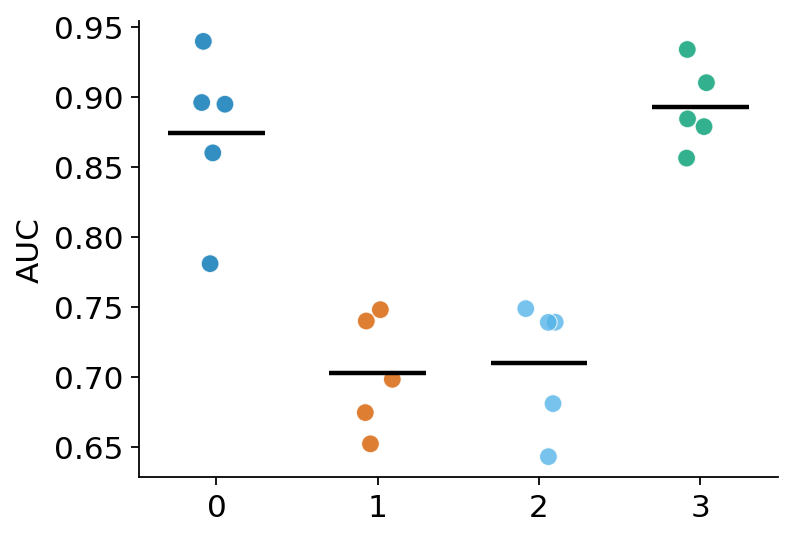

In [15]:
EMT_MAP = {0: "EPI", 1: "H-EPI", 2: "H-MES", 3: "MES"}
spice.pl.auc_per_class(adata, state_map=EMT_MAP, save=figures_dir + "xenium_v1_auc_per_class_hallmark.pdf")

Computing node explanations for label 0...


Label 0:   0%|          | 0/300 [00:00<?, ?it/s]

Label 0:   0%|          | 1/300 [00:20<1:40:58, 20.26s/it]

Label 0:   1%|          | 3/300 [00:40<1:03:48, 12.89s/it]

Label 0:   1%|▏         | 4/300 [01:01<1:16:32, 15.51s/it]

Label 0:   2%|▏         | 7/300 [01:21<50:18, 10.30s/it]  

... (986 outputs left out)

Permutation: 100%|█████████▉| 299/300 [1:41:39<00:20, 20.15s/it]

Permutation: 100%|██████████| 300/300 [1:41:59<00:00, 20.23s/it]

Permutation: 100%|██████████| 300/300 [1:41:59<00:00, 20.40s/it]

(<Figure size 1040x640 with 4 Axes>,
 array([<Axes: title={'center': 'EPI'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'H-EPI'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'H-MES'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'MES'}, ylabel='$-\\log_{10}(p)$'>],
       dtype=object))

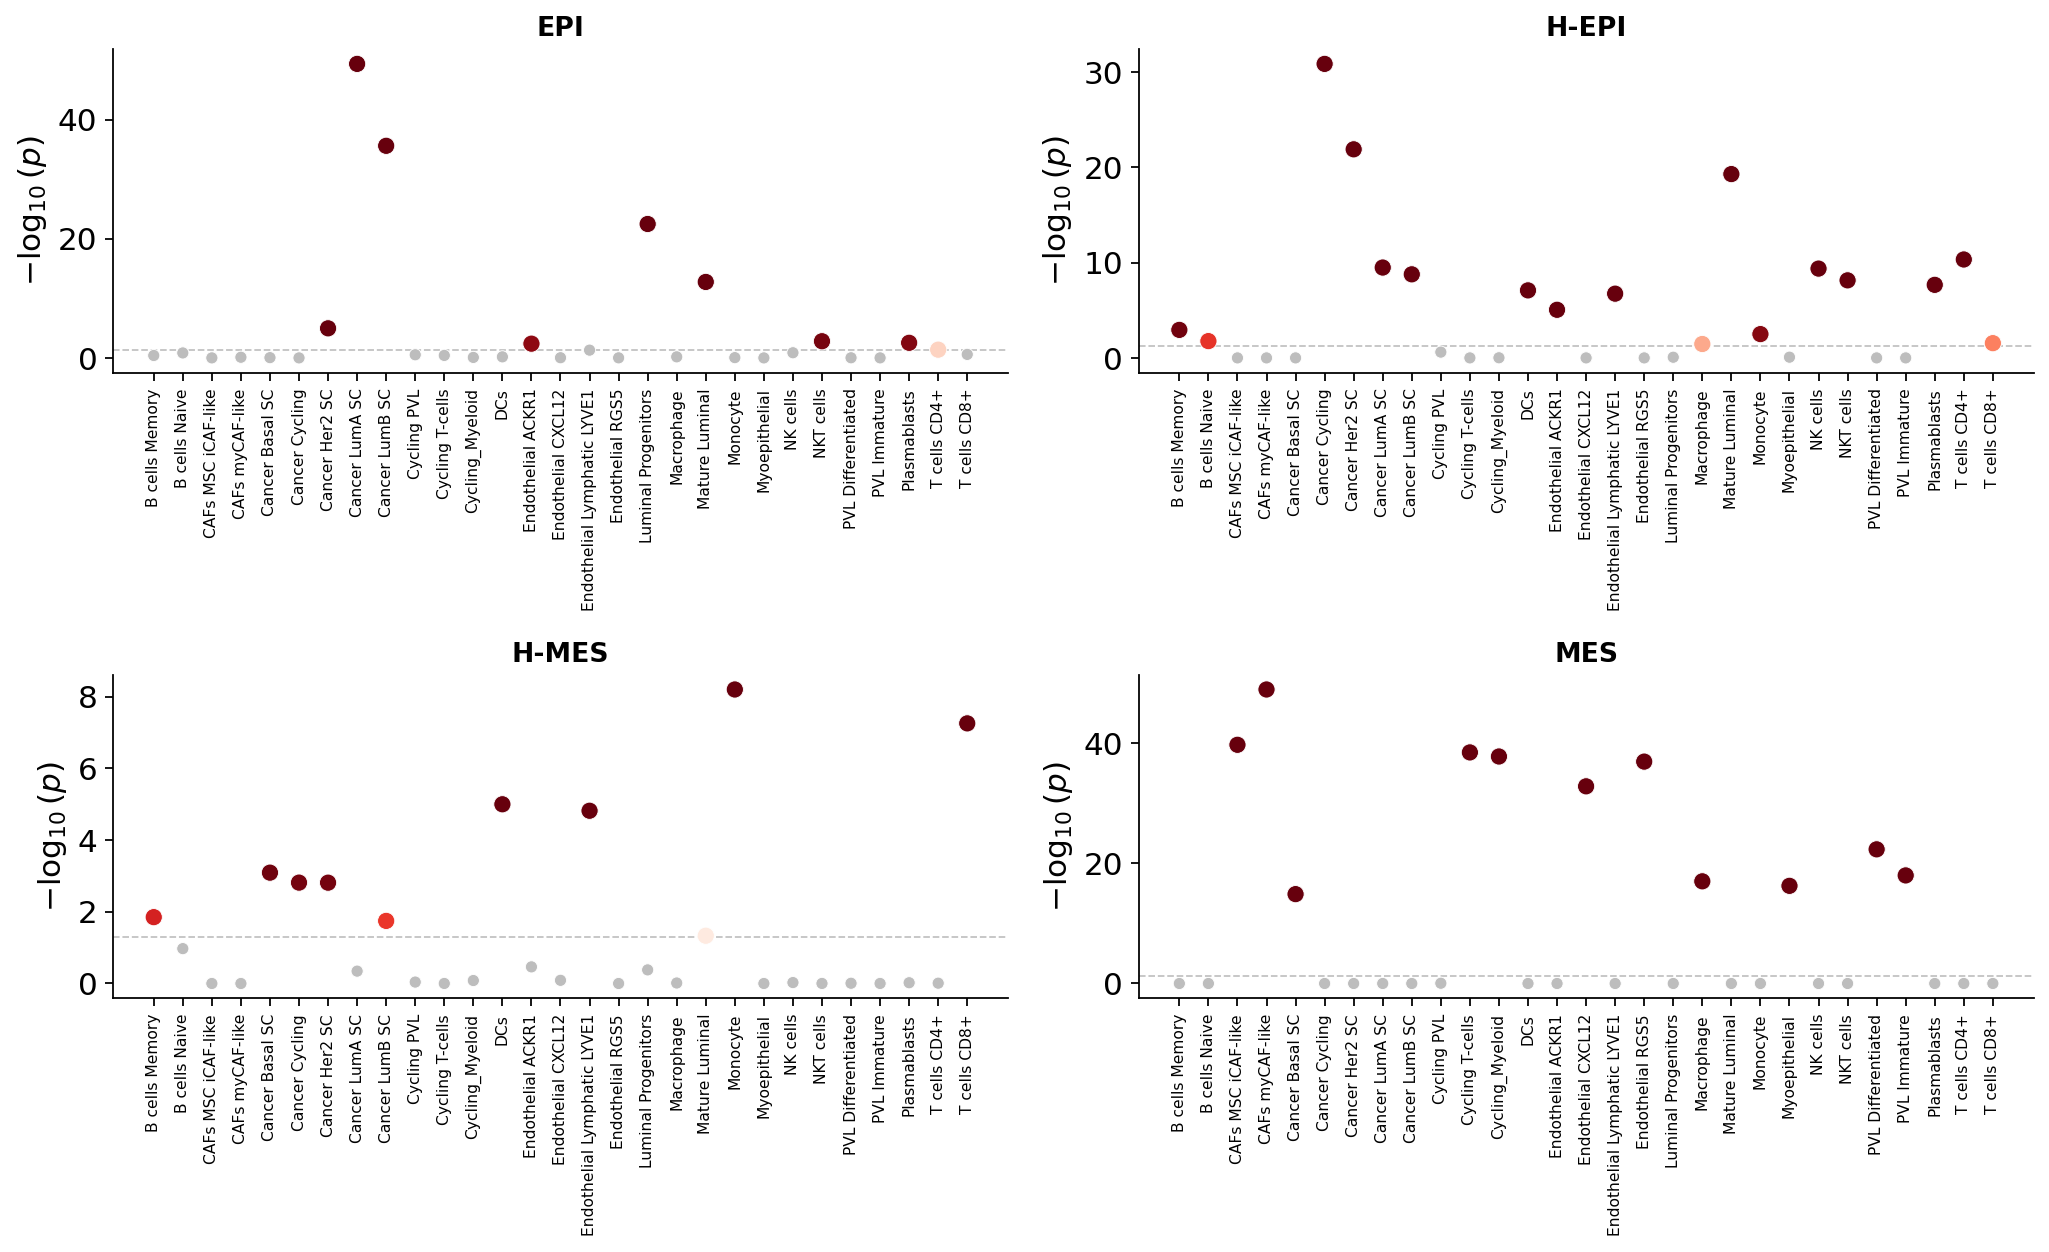

In [16]:
spice.tl.explain_nodes(adata, n_explanations=300)  # increase to 300 for publication quality
spice.pl.node_importance(
    adata, state_map=EMT_MAP, save=figures_dir + "xenium_v1_node_importance.pdf"
)

In [17]:
spice.tl.sanitize(adata)
adata.write_h5ad("processed_data/xenium_v1_hallmark_spice_results.h5ad")

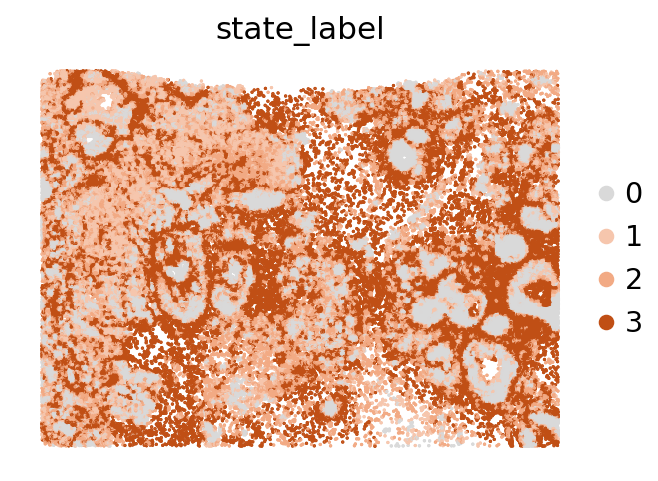

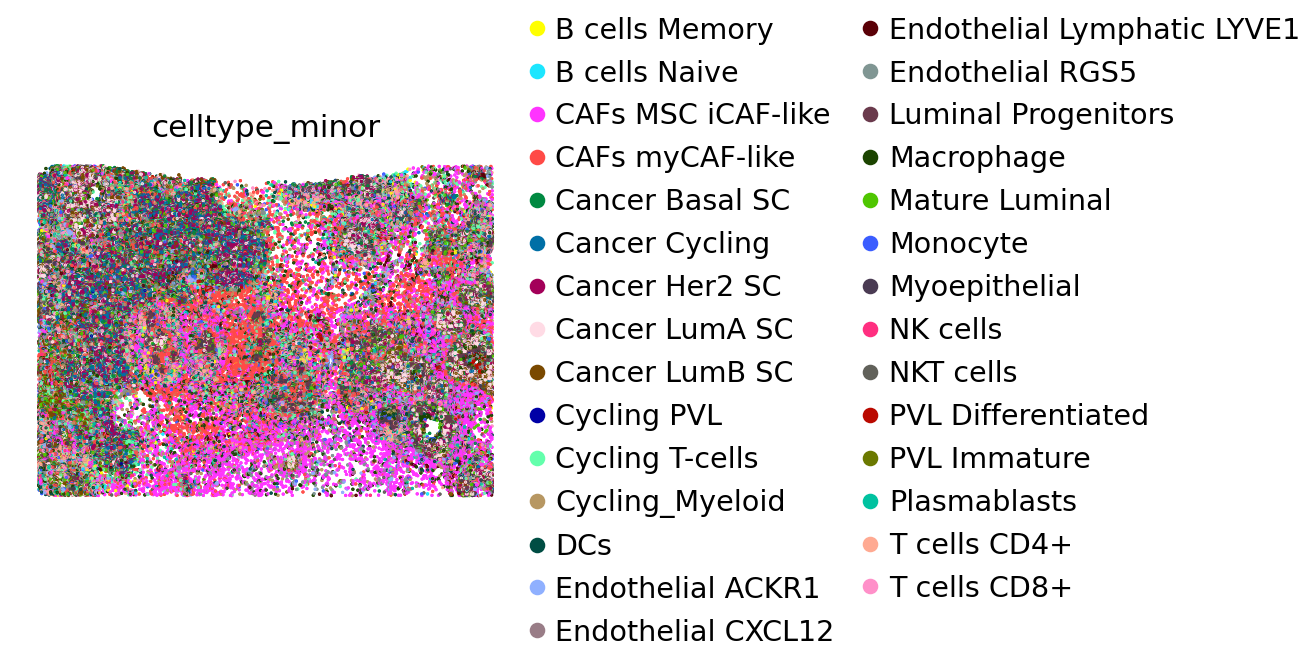

In [18]:
import squidpy as sq
import scanpy as sc

sc.set_figure_params(frameon=False)
adata.obs["state_label"] = adata.obs["state_label"].astype("category")
adata.uns["state_label_colors"] = ["#D9D9D9", "#F6C6AD", "#F2AA84", "#C04F15"]

sq.pl.spatial_scatter(
    adata,
    shape=None,
    color=["state_label"],
    save="xenium_v1_spatial_scatter_state_label.pdf",
)

sq.pl.spatial_scatter(
    adata,
    shape=None,
    color=["celltype_minor"],
    save="xenium_v1_spatial_scatter_cell_type.pdf",
)